In [4]:
%pip install --upgrade pip

   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----------- ---------------------------- 0.5/1.8 MB 708.3 kB/s eta 0:00:02
   ----------------- ---------------------- 0.8/1.8 MB 972.3 kB/s eta 0:00:02
   ---------------------------- ----------- 1.3/1.8 MB 1.1 MB/s eta 0:00:01
   ---------------------------------- ----- 1.6/1.8 MB 1.1 MB/s eta 0:00:01
   ---------------------------------------- 1.8/1.8 MB 1.2 MB/s  0:00:01
  Attempting uninstall: pip
    Found existing installation: pip 26.1.2
    Uninstalling pip-26.1.2:
      Successfully uninstalled pip-26.1.2
Note: you may need to restart the kernel to use updated packages.


In [5]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [7]:
%pip install opencv-python

  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.5/44.0 MB 1.3 MB/s eta 0:00:34
    --------------------------------------- 0.8/44.0 MB 1.3 MB/s eta 0:00:33
    --------------------------------------- 0.8/44.0 MB 1.3 MB/s eta 0:00:33
    --------------------------------------- 0.8/44.0 MB 1.3 MB/s eta 0:00:33
    --------------------------------------- 0.8/44.0 MB 1.3 MB/s eta 0:00:33
   - -------------------------------------- 1.8/44.0 MB 1.4 MB/s eta 0:00:31
   -- ------------------------------------- 2.6/44.0 MB 1.6 MB/s eta 0:00:27
   -- ------------------------------------- 2.6/44.0 MB 1.6 MB/s eta 0:00:27
   -- -------------------

In [8]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

print("NumPy:", np.__version__)
print("OpenCV:", cv.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("All libraries imported successfully!")

NumPy: 2.4.6
OpenCV: 5.0.0
Matplotlib: 3.11.0
All libraries imported successfully!


In [10]:
import os

print("Current folder:", os.getcwd())
print("Files in folder:", os.listdir())

Current folder: C:\Users\pc
Files in folder: ['.anaconda', '.cache', '.conda', '.continuum', '.copilot', '.icesoft', '.ipynb_checkpoints', '.ipython', '.jupyter', '.ms-ad', '.node_repl_history', '.npmrc', '.openjfx', '.packettracer', '.pdfbox.cache', '.python_history', '.qt-license', '.VirtualBox', '.vscode', '.vscode-shared', '.webgoat-2023.8', '3D Objects', 'anaconda', 'AppData', 'Application Data', 'Cisco Packet Tracer 9.0.0', 'Contacts', 'Cookies', 'cookies.txt', 'Desktop', 'Documents', 'Downloads', 'Favorites', 'IntelGraphicsProfiles', 'Lab02.ipynb', 'Links', 'Local Settings', 'Music', 'My Documents', 'my-react-app', 'NetHood', 'New folder', 'New folder (2)', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{53b39e88-18c4-11ea-a811-000d3aa4692b}.TM.blf', 'NTUSER.DAT{53b39e88-18c4-11ea-a811-000d3aa4692b}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{53b39e88-18c4-11ea-a811-000d3aa4692b}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'OneDrive'

In [11]:
image_path = r"C:\Users\pc\Desktop\dip-lab-02\my_image.jpg"

image_bgr = cv.imread(image_path)

if image_bgr is None:
    raise FileNotFoundError("Image nahi mili. File ka naam check karo.")

print("Image loaded successfully!")
print("Image shape:", image_bgr.shape)
print("Data type:", image_bgr.dtype)

Image loaded successfully!
Image shape: (352, 236, 3)
Data type: uint8


In [12]:
# Image ki height, width aur channels
height, width, channels = image_bgr.shape

print("Height:", height)
print("Width:", width)
print("Number of channels:", channels)

# Top-left pixel
print("Top-left pixel (BGR):", image_bgr[0, 0])

# Center pixel
print(
    "Center pixel (BGR):",
    image_bgr[height // 2, width // 2]
)

# Global minimum aur maximum
print("Global minimum:", image_bgr.min())
print("Global maximum:", image_bgr.max())

# Har channel ka minimum aur maximum
print("Channel minimums (B, G, R):", image_bgr.min(axis=(0, 1)))
print("Channel maximums (B, G, R):", image_bgr.max(axis=(0, 1)))

Height: 352
Width: 236
Number of channels: 3
Top-left pixel (BGR): [174 186 190]
Center pixel (BGR): [116 140 168]
Global minimum: 0
Global maximum: 255
Channel minimums (B, G, R): [0 0 8]
Channel maximums (B, G, R): [235 246 255]


Center pixel RGB: [168 140 116]
Center pixel HEX: #A88C74


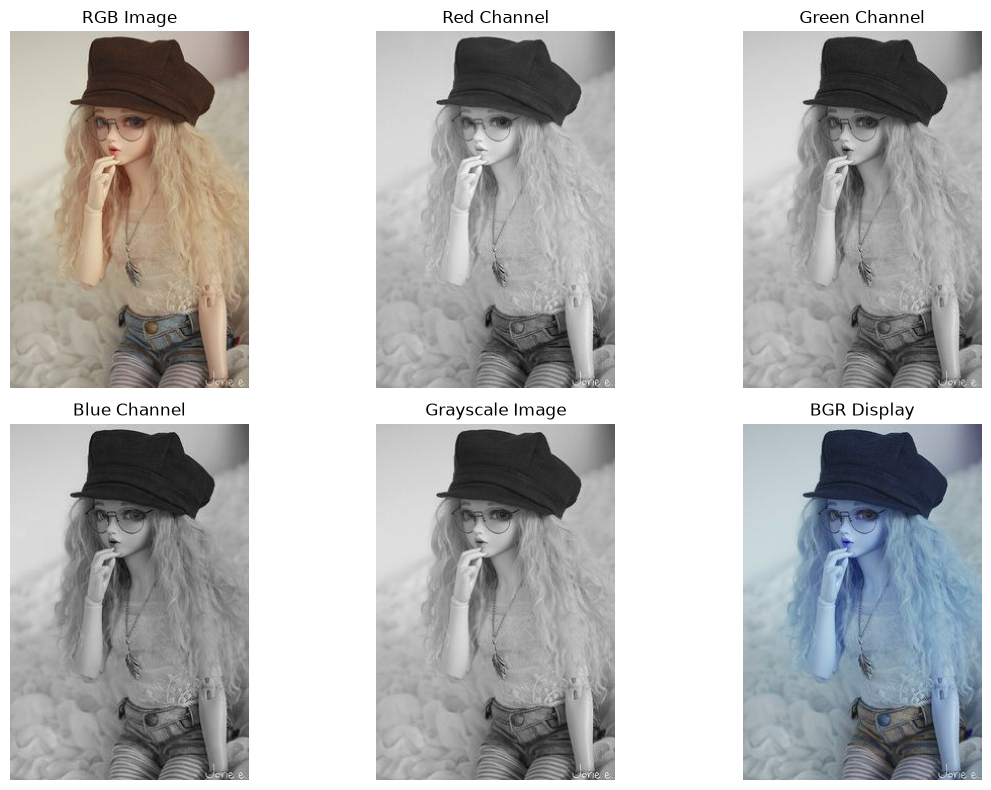

In [13]:
# BGR se RGB conversion
image_rgb = cv.cvtColor(image_bgr, cv.COLOR_BGR2RGB)

# Grayscale image
gray = cv.cvtColor(image_bgr, cv.COLOR_BGR2GRAY)

# Red, Green aur Blue channels
red = image_rgb[:, :, 0]
green = image_rgb[:, :, 1]
blue = image_rgb[:, :, 2]

# Center pixel ka RGB aur HEX color
center_rgb = image_rgb[height // 2, width // 2]
r, g, b = map(int, center_rgb)
hex_color = f"#{r:02X}{g:02X}{b:02X}"

print("Center pixel RGB:", center_rgb)
print("Center pixel HEX:", hex_color)

# Six views
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

images = [
    (image_rgb, "RGB Image", None),
    (red, "Red Channel", "gray"),
    (green, "Green Channel", "gray"),
    (blue, "Blue Channel", "gray"),
    (gray, "Grayscale Image", "gray"),
    (image_bgr, "BGR Display", None)
]

for ax, (img, title, cmap) in zip(axes.flat, images):
    ax.imshow(img, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

Crop shape: (100, 100, 3)


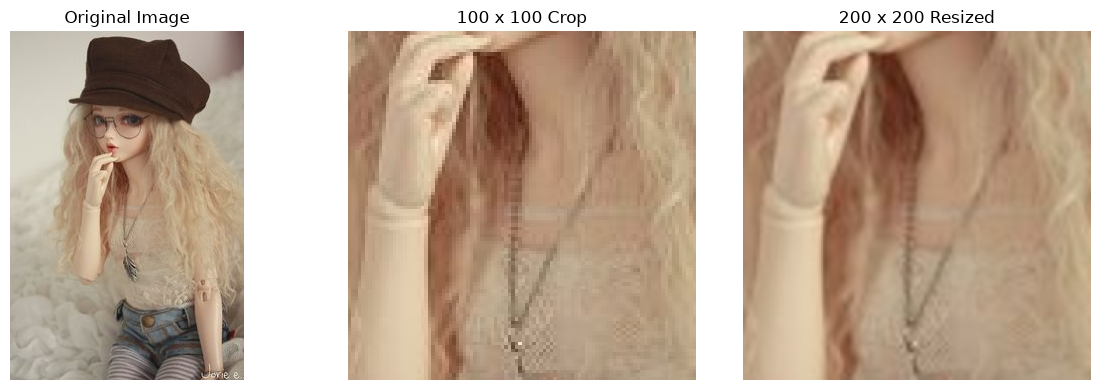

Image saved successfully: True


In [14]:
# Image ke center se exact 100 x 100 crop
y_start = height // 2 - 50
x_start = width // 2 - 50

crop_bgr = image_bgr[
    y_start:y_start + 100,
    x_start:x_start + 100
]

print("Crop shape:", crop_bgr.shape)

# Crop ko RGB mein convert karo
crop_rgb = cv.cvtColor(crop_bgr, cv.COLOR_BGR2RGB)

# Resize to 200 x 200
resized_rgb = cv.resize(crop_rgb, (200, 200))

# Three images display karo
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(image_rgb)
axes[0].set_title("Original Image")

axes[1].imshow(crop_rgb)
axes[1].set_title("100 x 100 Crop")

axes[2].imshow(resized_rgb)
axes[2].set_title("200 x 200 Resized")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Save resized image
resized_bgr = cv.cvtColor(resized_rgb, cv.COLOR_RGB2BGR)
saved = cv.imwrite("resized_crop.png", resized_bgr)

print("Image saved successfully:", saved)

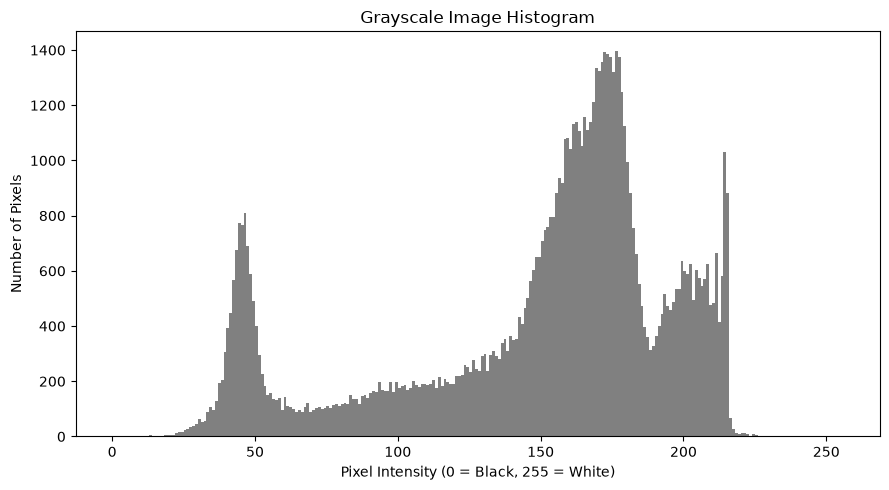

Histogram saved successfully!


In [15]:
# Grayscale pixels ko one-dimensional array mein convert karo
gray_pixels = gray.flatten()

# Histogram banao
plt.figure(figsize=(9, 5))

plt.hist(
    gray_pixels,
    bins=256,
    range=(0, 256),
    color="gray"
)

plt.title("Grayscale Image Histogram")
plt.xlabel("Pixel Intensity (0 = Black, 255 = White)")
plt.ylabel("Number of Pixels")

plt.tight_layout()

# Histogram save karo
plt.savefig("grayscale_histogram.png")
plt.show()

print("Histogram saved successfully!")

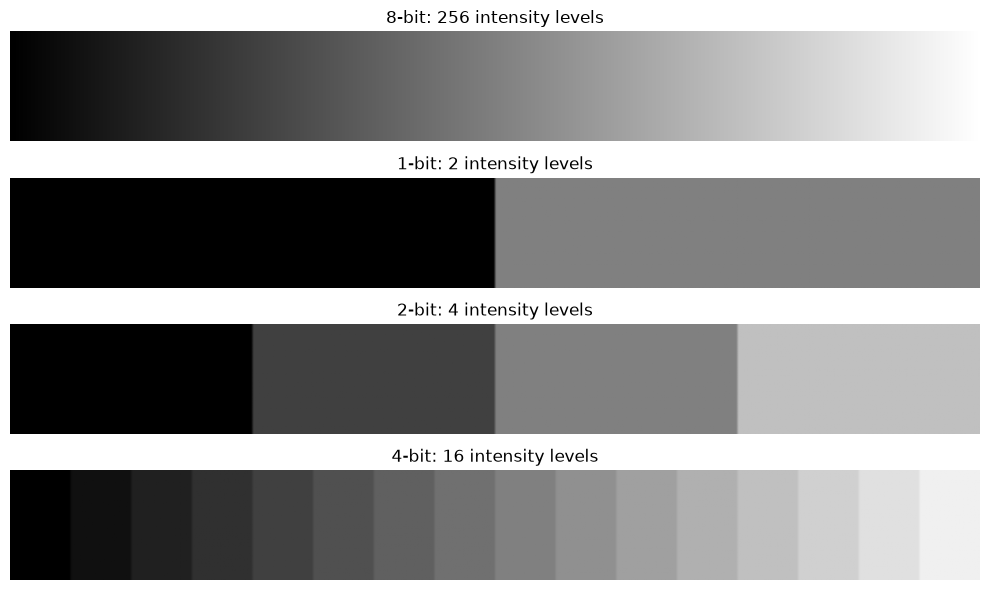

8-bit unique values: 256
1-bit unique values: 2
2-bit unique values: 4
4-bit unique values: 16


In [16]:
# 8-bit grayscale gradient: 0 se 255
gradient = np.arange(256, dtype=np.uint8)
gradient = np.tile(gradient, (50, 1))

# Different bit depths mein convert karne ka function
def quantize_image(image, bits):
    levels = 2 ** bits
    step = 256 / levels

    quantized = np.floor(image / step) * step
    return quantized.astype(np.uint8)

# 1-bit, 2-bit aur 4-bit gradients
gradient_1bit = quantize_image(gradient, 1)
gradient_2bit = quantize_image(gradient, 2)
gradient_4bit = quantize_image(gradient, 4)

# Charon gradients display karo
fig, axes = plt.subplots(4, 1, figsize=(10, 6))

gradients = [
    (gradient, "8-bit: 256 intensity levels"),
    (gradient_1bit, "1-bit: 2 intensity levels"),
    (gradient_2bit, "2-bit: 4 intensity levels"),
    (gradient_4bit, "4-bit: 16 intensity levels")
]

for ax, (img, title) in zip(axes, gradients):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255, aspect="auto")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Unique intensity values count karo
print("8-bit unique values:", len(np.unique(gradient)))
print("1-bit unique values:", len(np.unique(gradient_1bit)))
print("2-bit unique values:", len(np.unique(gradient_2bit)))
print("4-bit unique values:", len(np.unique(gradient_4bit)))